In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [3]:
df = pd.read_csv("../data/clean_chicago_crimes.csv")

print("Dataset shape:", df.shape)
df.head()

Dataset shape: (1388164, 20)


,id,date,primary_type,description,location_description,arrest,domestic,beat,district,ward,community_area,year,latitude,longitude,hour,day_of_week,month,month_name,season,year_month
0,25699,2021-01-01 03:48:00,HOMICIDE,FIRST DEGREE MURDER,AUTO,False,False,224,2,3.0,38.0,2021,41.808891,-87.616577,3,Friday,1,January,Winter,2021-01
1,25700,2021-01-01 18:06:00,HOMICIDE,FIRST DEGREE MURDER,STREET,False,False,1532,15,28.0,25.0,2021,41.885721,-87.747018,18,Friday,1,January,Winter,2021-01
2,25701,2021-01-02 21:55:00,HOMICIDE,FIRST DEGREE MURDER,STREET,False,False,1022,10,24.0,29.0,2021,41.858214,-87.704772,21,Saturday,1,January,Winter,2021-01
3,25702,2021-01-03 20:09:00,HOMICIDE,FIRST DEGREE MURDER,STREET,False,False,332,3,5.0,43.0,2021,41.771062,-87.586271,20,Sunday,1,January,Winter,2021-01
4,25703,2021-01-03 21:28:00,HOMICIDE,FIRST DEGREE MURDER,APARTMENT,True,False,424,4,10.0,46.0,2021,41.736660,-87.544454,21,Sunday,1,January,Winter,2021-01


In [4]:
df['date'] = pd.to_datetime(
    df['date'],
    errors='coerce'
)

print(df['date'].min())
print(df['date'].max())

2021-01-01 00:00:00
2026-10-03 00:00:00


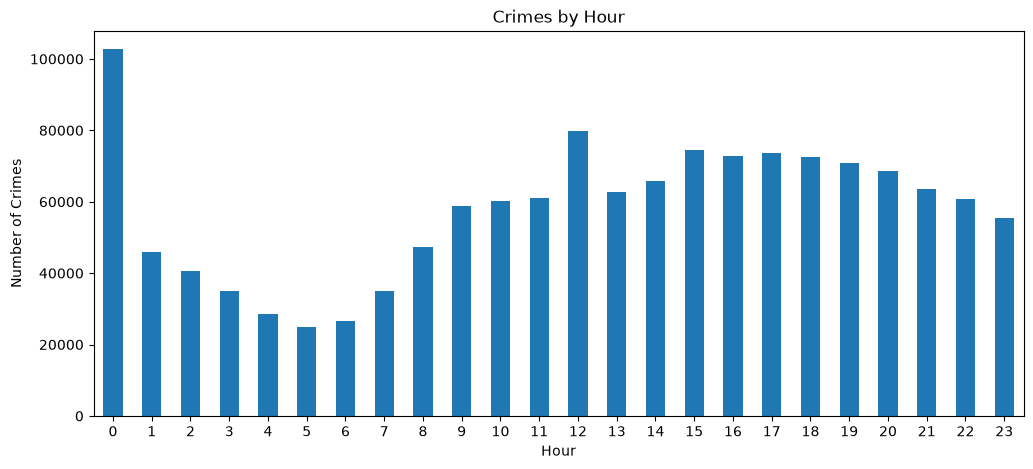

In [5]:
hourly_crimes = df.groupby('hour').size()

hourly_crimes.plot(
    kind='bar',
    figsize=(12, 5),
    title='Crimes by Hour'
)

plt.xlabel('Hour')
plt.ylabel('Number of Crimes')
plt.xticks(rotation=0)
plt.show()

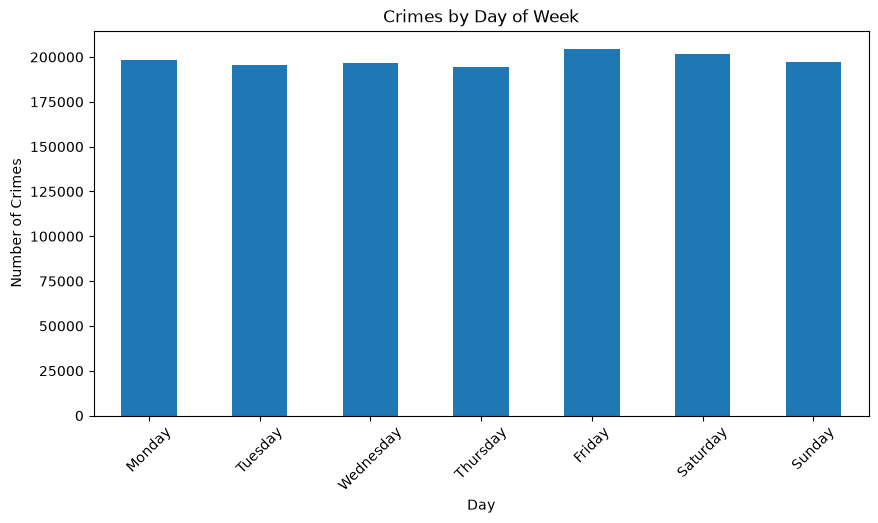

In [6]:
day_order = [
    'Monday',
    'Tuesday',
    'Wednesday',
    'Thursday',
    'Friday',
    'Saturday',
    'Sunday'
]

daily_crimes = (
    df['day_of_week']
    .value_counts()
    .reindex(day_order)
)

daily_crimes.plot(
    kind='bar',
    figsize=(10, 5),
    title='Crimes by Day of Week'
)

plt.xlabel('Day')
plt.ylabel('Number of Crimes')
plt.xticks(rotation=45)
plt.show()

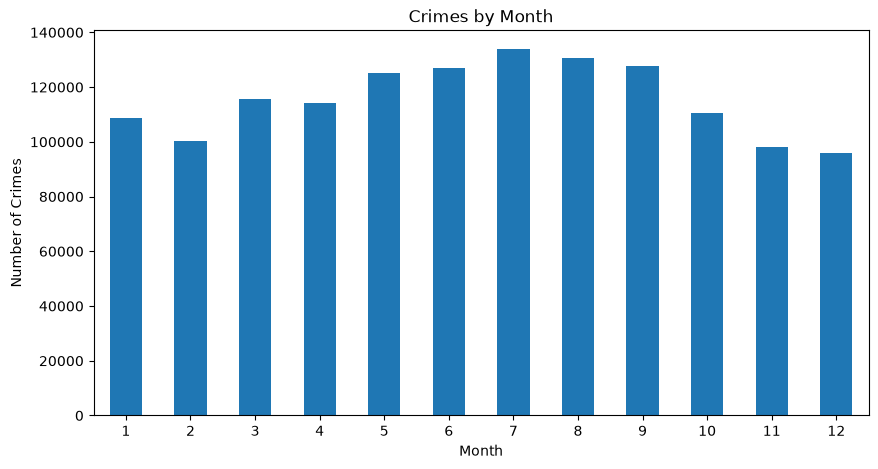

In [7]:
monthly_crimes = (
    df.groupby('month')
    .size()
    .sort_index()
)

monthly_crimes.plot(
    kind='bar',
    figsize=(10, 5),
    title='Crimes by Month'
)

plt.xlabel('Month')
plt.ylabel('Number of Crimes')
plt.xticks(rotation=0)
plt.show()

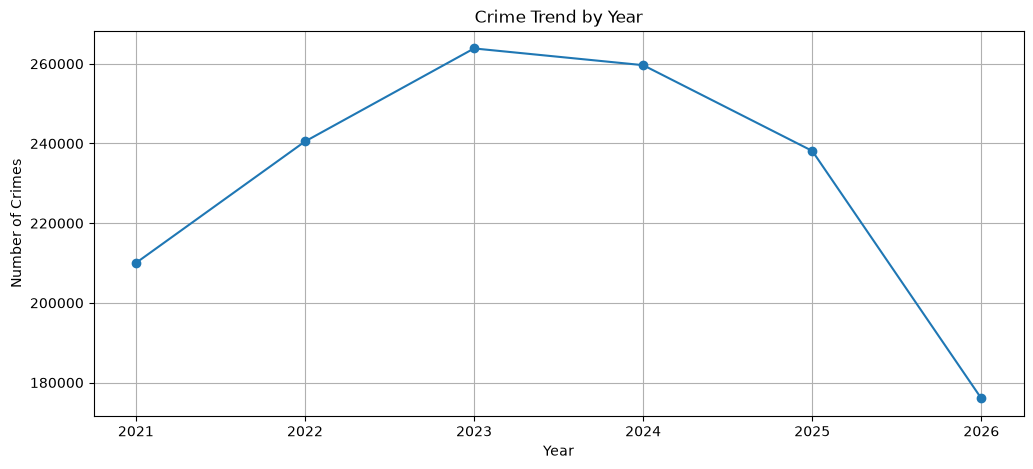

In [8]:
yearly_crimes = (
    df.groupby('year')
    .size()
    .sort_index()
)

yearly_crimes.plot(
    figsize=(12, 5),
    marker='o',
    title='Crime Trend by Year'
)

plt.xlabel('Year')
plt.ylabel('Number of Crimes')
plt.grid()
plt.show()


In [9]:
day_mapping = {
    'Monday': 0,
    'Tuesday': 1,
    'Wednesday': 2,
    'Thursday': 3,
    'Friday': 4,
    'Saturday': 5,
    'Sunday': 6
}

df['day_num'] = df['day_of_week'].map(day_mapping)

In [10]:
df['hour_sin'] = np.sin(
    2 * np.pi * df['hour'] / 24
)

df['hour_cos'] = np.cos(
    2 * np.pi * df['hour'] / 24
)


In [11]:
df['day_sin'] = np.sin(
    2 * np.pi * df['day_num'] / 7
)

df['day_cos'] = np.cos(
    2 * np.pi * df['day_num'] / 7
)


In [12]:
df['month_sin'] = np.sin(
    2 * np.pi * (df['month'] - 1) / 12
)

df['month_cos'] = np.cos(
    2 * np.pi * (df['month'] - 1) / 12
)

In [13]:
temporal_features = [
    'hour',
    'hour_sin',
    'hour_cos',
    'day_of_week',
    'day_num',
    'day_sin',
    'day_cos',
    'month',
    'month_sin',
    'month_cos'
]

df[temporal_features].head(10)


,hour,hour_sin,hour_cos,day_of_week,day_num,day_sin,day_cos,month,month_sin,month_cos
0,3,0.707107,7.071068e-01,Friday,4,-0.433884,-0.900969,1,0.0,1.0
1,18,-1.000000,-1.836970e-16,Friday,4,-0.433884,-0.900969,1,0.0,1.0
2,21,-0.707107,7.071068e-01,Saturday,5,-0.974928,-0.222521,1,0.0,1.0
3,20,-0.866025,5.000000e-01,Sunday,6,-0.781831,0.623490,1,0.0,1.0
4,21,-0.707107,7.071068e-01,Sunday,6,-0.781831,0.623490,1,0.0,1.0
5,19,-0.965926,2.588190e-01,Monday,0,0.000000,1.000000,1,0.0,1.0
6,20,-0.866025,5.000000e-01,Monday,0,0.000000,1.000000,1,0.0,1.0
7,22,-0.500000,8.660254e-01,Monday,0,0.000000,1.000000,1,0.0,1.0
8,19,-0.965926,2.588190e-01,Tuesday,1,0.781831,0.623490,1,0.0,1.0
9,5,0.965926,2.588190e-01,Wednesday,2,0.974928,-0.222521,1,0.0,1.0


In [15]:
df.to_csv(
    "../data/crimes_features.csv",
    index=False
)

print("crimes_features.csv saved ✅")
print("Final shape:", df.shape)

crimes_features.csv saved ✅
Final shape: (1388164, 27)
